In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv("train.csv")
print(df.head())
print("Shape:", df.shape)

   Id MSZoning Neighborhood HouseStyle  OverallQual  OverallCond  YearBuilt  \
0   1       RL      Somerst     1Story            7            8       2019   
1   2       RL      OldTown     1Story            6            5       1985   
2   3       RL      Edwards     1Story            8            5       2013   
3   4       RL      CollgCr     1Story            7            4       2020   
4   5       RL      Edwards     1.5Fin            4            6       2011   

   LotArea  GrLivArea  TotalBsmtSF  BedroomAbvGr  FullBath  GarageCars  \
0  11780.0       1820       1158.0             3         2         1.0   
1  10188.0       1384        626.0             2         2         2.0   
2  11090.0       1548       1184.0             5         2         1.0   
3   7386.0       1481        862.0             2         1         2.0   
4   8961.0       1692       1356.0             2         2         2.0   

   SalePrice  
0     294780  
1     235803  
2     277399  
3     276582  
4    

In [8]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            200 non-null    int64  
 1   MSZoning      200 non-null    object 
 2   Neighborhood  198 non-null    object 
 3   HouseStyle    200 non-null    object 
 4   OverallQual   200 non-null    int64  
 5   OverallCond   200 non-null    int64  
 6   YearBuilt     200 non-null    int64  
 7   LotArea       197 non-null    float64
 8   GrLivArea     200 non-null    int64  
 9   TotalBsmtSF   197 non-null    float64
 10  BedroomAbvGr  200 non-null    int64  
 11  FullBath      200 non-null    int64  
 12  GarageCars    198 non-null    float64
 13  SalePrice     200 non-null    int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 22.0+ KB
None
               Id  OverallQual  OverallCond    YearBuilt       LotArea  \
count  200.000000   200.000000   200.000000   200.000000    197.0

In [9]:
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

LotArea         3
TotalBsmtSF     3
Neighborhood    2
GarageCars      2
dtype: int64


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


count       200.000000
mean     244826.970000
std       51595.886982
min      106935.000000
25%      211017.250000
50%      241178.000000
75%      278318.750000
max      480000.000000
Name: SalePrice, dtype: float64


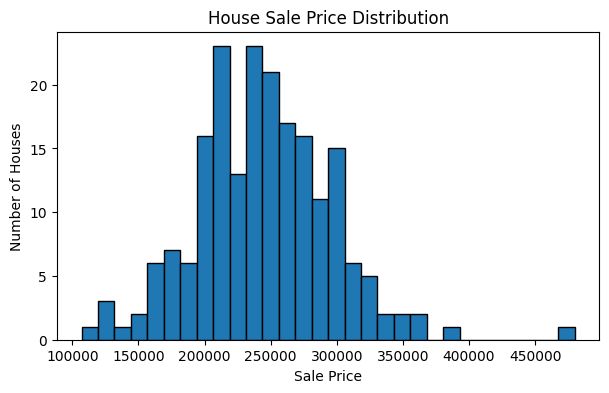

In [11]:
print(df["SalePrice"].describe())
plt.figure(figsize=(7, 4))
plt.hist(df["SalePrice"], bins=30, edgecolor="black")
plt.title("House Sale Price Distribution")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.show()

OverallQual
3    221385.666667
4    213940.454545
5    219146.470588
6    247669.375000
7    267328.270833
8    263306.105263
9    338536.166667
Name: SalePrice, dtype: float64


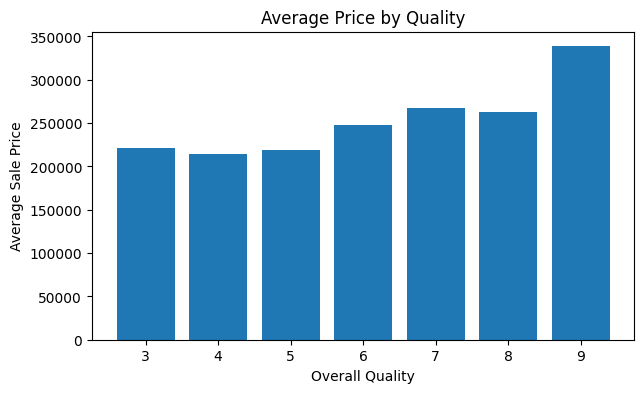

In [12]:
quality_price = df.groupby("OverallQual")["SalePrice"].mean()
print(quality_price)
plt.figure(figsize=(7, 4))
plt.bar(quality_price.index, quality_price.values)
plt.xlabel("Overall Quality")
plt.ylabel("Average Sale Price")
plt.title("Average Price by Quality")
plt.show()

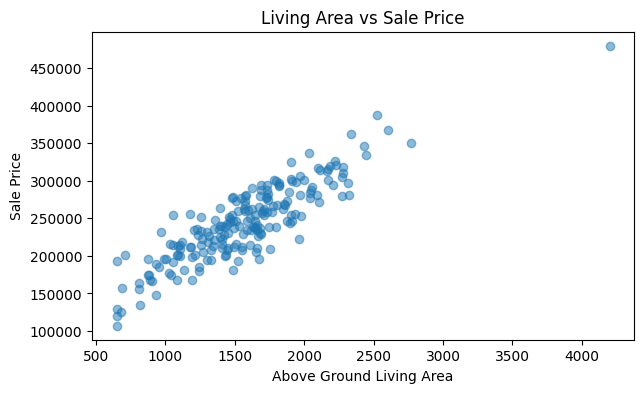

In [13]:
plt.figure(figsize=(7, 4))
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.5)
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")
plt.title("Living Area vs Sale Price")
plt.show()

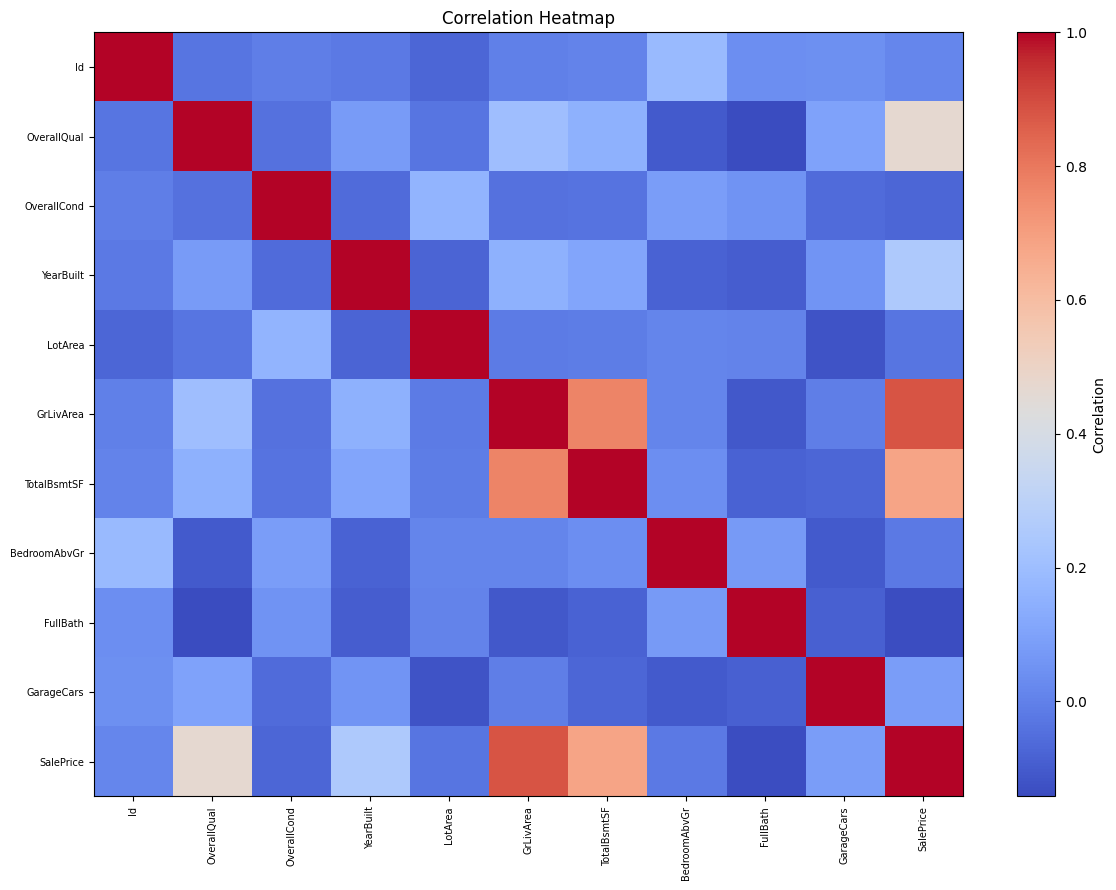

In [14]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
plt.figure(figsize=(12, 9))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=7)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()